# Clustering dan Klasifikasi

## A. Tugas Clustering / Segmentasi Polutan

Tugas yang dikerjakan:

1. **Menggabungkan 3 polutan menjadi 204 kolom fitur**

   Data yang digunakan terdiri dari **NO₂, CO, dan SO₂**. Masing-masing polutan menghasilkan **68 fitur TSFEL**, sehingga:

   `3 polutan × 68 fitur = 204 fitur`.

   Proses ini dilakukan untuk dua jenis preprocessing/interpolasi, yaitu **Linear** dan **Polynomial**, sehingga tersedia dua dataset fitur: hasil Linear dan hasil Polynomial.

2. **Melakukan reduksi dimensi 203, 74, dan 37**

   Dari 204 fitur tersebut dilakukan eksperimen PCA dengan tiga ukuran dimensi:
   - PCA 203
   - PCA 74
   - PCA 37

   Ketiga konfigurasi tersebut digunakan untuk melihat pengaruh jumlah dimensi terhadap hasil clustering.

3. **Memberikan hasil clustering pada setiap dimensi**

   Setiap hasil reduksi dimensi diuji menggunakan **K-Means** dengan beberapa jumlah cluster:
   - `K = 3`
   - `K = 5`
   - `K = 7`

   Dengan demikian, hasil clustering dibandingkan pada berbagai kombinasi metode, jumlah dimensi, dan jumlah cluster.

4. **Melakukan eksperimen untuk mencari cluster terbaik menggunakan Silhouette Coefficient**

   Nilai **Silhouette Coefficient** digunakan sebagai ukuran kualitas pemisahan cluster. Nilai yang lebih tinggi menunjukkan hasil clustering yang lebih baik.

   Hasil terbaik yang diperoleh:
   - **Linear:** PCA 37, K=3, Silhouette = **0,647**
   - **Polynomial:** PCA 37, K=7, Silhouette = **0,537**

   Sehingga hasil terbaik secara keseluruhan adalah **Linear + PCA 37 + K=3**.

5. **Menampilkan hasil clustering pada peta**

   Hasil cluster kemudian divisualisasikan pada peta menggunakan **Python/Folium**. Setiap cluster diberi warna berbeda dan setiap titik dapat dibuka untuk melihat nama, daerah, cluster, dan koordinat.

---

## B. Tugas Klasifikasi Sawah / Non-Sawah

Tugas yang dikerjakan:

1. **Menggunakan 50 sampel sawah**

   Dataset training memiliki **50 sampel berlabel `sawah`**.

2. **Menggunakan 50 sampel non-sawah**

   Dataset training memiliki **50 sampel berlabel `non_sawah`**.

   Total data training:

   `50 sawah + 50 non-sawah = 100 sampel`.

3. **Melakukan klasifikasi 2 kelas**

   Target klasifikasi terdiri dari dua kelas:
   - `sawah`
   - `non_sawah`

4. **Menggunakan citra Sentinel-2A**

   Data citra yang digunakan berasal dari **Sentinel-2A** dan disimpan dalam format **GeoTIFF/TIF**. Raster yang digunakan memiliki resolusi sekitar 10 meter dan digunakan sebagai sumber data untuk proses klasifikasi pixel.

5. **Menggunakan fitur spektral dari raster**

   Pada proses klasifikasi digunakan fitur:
   - B02
   - B03
   - B04
   - B08

   Fitur tersebut digunakan untuk melatih model klasifikasi dan kemudian memprediksi kelas setiap pixel pada raster Sentinel-2A.

6. **Menampilkan hasil klasifikasi pada peta**

   Hasil klasifikasi disimpan sebagai GeoTIFF dengan kode:
   - `0` = Non-Sawah
   - `1` = Sawah
   - `255` = NoData

   Raster hasil kemudian ditampilkan kembali menggunakan Python sehingga hasil klasifikasi dapat dilihat sebagai peta.


## Band sentinel 2A

band sentinel 2A
mendeskripsikan macam macam band pada sentinel 2A
- NDVI
- B02

## 1. Import library

Kode berikut mengimpor library yang digunakan untuk membaca data, membuat tabel, membuat peta interaktif, dan menampilkan raster.

In [1]:
from pathlib import Path
import re
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

import folium
from folium.plugins import MiniMap

import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


## 2. Menentukan lokasi file

Kode berikut menentukan folder project dan lokasi file CSV, GeoTIFF, serta data training.

### Apa yang dilakukan

Path dibuat relatif terhadap folder project agar notebook dapat menemukan file input dan output tanpa menulis path satu per satu pada setiap bagian kode.

In [2]:
BASE = Path.cwd()

# Jika notebook tidak dijalankan dari root project, cari parent
# yang memiliki folder data.
if not (BASE / "data").exists():
    for parent in BASE.parents:
        if (parent / "data").exists():
            BASE = parent
            break

OUTPUT = BASE / "data" / "output"
TRAINING = BASE / "data" / "training"
SENTINEL = BASE / "data" / "sentinel2"

LINEAR_CSV = OUTPUT / "clustering_linear_final.csv"
POLY_CSV = OUTPUT / "clustering_polynomial_final.csv"
SAMPLES_CSV = TRAINING / "sentinel2_samples.csv"
RASTER_CLS = OUTPUT / "klasifikasi_sawah_knn.tif"
RASTER_S2 = SENTINEL / "menganti_sentinel2_2026-10-01.tif"

print("Project :", BASE)


Project : d:\Projects\Kuliah\PSD


### Ringkasan bagian clustering pada notebook

Bagian clustering di bawah digunakan untuk membaca hasil eksperimen dari kombinasi **3 polutan → 204 fitur**, **PCA 203/74/37**, dan **K-Means K=3/5/7**, kemudian menampilkan distribusi cluster dan hasilnya pada peta.

## 3. Membaca hasil clustering

Kode berikut membaca hasil clustering Linear dan Polynomial yang berisi `id`, `nama`, `daerah`, dan `Cluster`.

### Apa yang dilakukan

Dua CSV hasil clustering dibaca menjadi DataFrame. File Linear berisi hasil konfigurasi terbaik Linear, sedangkan file Polynomial berisi hasil konfigurasi terbaik Polynomial.

In [3]:
linear_df = pd.read_csv(LINEAR_CSV)
poly_df = pd.read_csv(POLY_CSV)

print("Linear :", linear_df.shape)
print("Polynomial :", poly_df.shape)

display(linear_df.head())
display(poly_df.head())


Linear : (37, 4)
Polynomial : (37, 4)


,Cluster,id,nama,daerah
0,cluster_1,1,Muhammad Ali Murtadho,Baron Nganjuk
1,cluster_0,2,Ainur Raftuzzaki,Nunukan
2,cluster_1,4,M. Hendrik Purwanto,"Sreseh, Sampang"
3,cluster_1,6,Okan Syailendra wahyudi,"Manyar, Gresik"
4,cluster_1,10,Muhammad Zaidan Nabil Rafi,"Kamal, Bangkalan"


,Cluster,id,nama,daerah
0,cluster_2,1,Muhammad Ali Murtadho,Baron Nganjuk
1,cluster_1,2,Ainur Raftuzzaki,Nunukan
2,cluster_2,4,M. Hendrik Purwanto,"Sreseh, Sampang"
3,cluster_4,6,Okan Syailendra wahyudi,"Manyar, Gresik"
4,cluster_0,9,Muhammad Zaidan Nabil Rafi,"Kamal, Bangkalan"


## 4. Menampilkan distribusi cluster

Kode berikut menghitung jumlah mahasiswa pada setiap cluster.

### Apa yang dilakukan

Jumlah data pada setiap label cluster dihitung agar distribusi hasil clustering dapat dilihat sebelum divisualisasikan pada peta.

In [4]:
print("Distribusi Linear")
display(
    linear_df["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Jumlah")
)

print("Distribusi Polynomial")
display(
    poly_df["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Jumlah")
)


Distribusi Linear


,Cluster,Jumlah
0,cluster_0,5
1,cluster_1,28
2,cluster_2,4


Distribusi Polynomial


,Cluster,Jumlah
0,cluster_0,1
1,cluster_1,2
2,cluster_2,8
3,cluster_3,4
4,cluster_4,8
5,cluster_5,4
6,cluster_6,10


## 5. Menyiapkan koordinat daerah

Kode berikut membersihkan nama daerah, mencocokkan daerah dengan koordinat, dan memberikan sedikit pergeseran deterministik pada marker agar titik yang berdekatan tidak saling menutupi.

### Apa yang dilakukan

Nama daerah dibersihkan lalu dicocokkan dengan kamus koordinat. `deterministic_jitter()` memberi pergeseran kecil yang konsisten agar marker dari daerah yang sama tidak bertumpuk sempurna.

In [5]:
COORDS = {
    'baron': (-7.6033, 112.0601),
    'nunukan': (4.1357, 117.6531),
    'sreseh': (-7.1983, 113.0805),
    'manyar': (-7.1192, 112.5975),
    'kamal': (-7.1662, 112.7214),
    'kedungpring': (-7.2181, 112.1931),
    'gresik kota': (-7.1566, 112.6555),
    'waru pamekasan': (-6.9634, 113.5350),
    'waru': (-6.9634, 113.5350),
    'paciran': (-6.8767, 112.3414),
    'kertosono': (-7.5878, 112.1006),
    'jabon': (-7.5419, 112.7686),
    'menganti': (-7.2618, 112.5857),
    'banyu ajuh': (-7.1585, 112.7280),
    'bandung jogoroto': (-7.5683, 112.2856),
    'widang': (-6.9850, 112.1647),
    'wonoayu': (-7.4338, 112.6172),
    'kwanyar': (-7.1604, 112.8569),
    'sambeng': (-7.2882, 112.2783),
    'kalianget': (-7.0519, 113.9408),
    'cerme': (-7.2281, 112.5583),
    'tikala': (1.4820, 124.8540),
    'kerek': (-6.8778, 111.9169),
    'wonokromo': (-7.3006, 112.7383),
    'asemrowo': (-7.2519, 112.7103),
    'kota sumenep': (-7.0086, 113.8617),
    'socah': (-7.0983, 112.7289),
    'pilangkenceng': (-7.4931, 111.6664),
    'tanah merah': (-7.0931, 112.8286),
    'labang': (-7.1294, 112.7936),
    'widodaren': (-7.3918, 111.2081),
    'bangkalan': (-7.0455, 112.7351),
    'warudoyong': (-6.9298, 106.9161),
    'banyuajuh': (-7.1620, 112.7310),
    'dukun': (-6.9903, 112.5186),
    'kecamatan bangkalan': (-7.0325, 112.7450),
}

COLORS = {
    'Cluster 0': '#e53935',
    'Cluster 1': '#1e88e5',
    'Cluster 2': '#43a047',
    'Cluster 3': '#fb8c00',
    'Cluster 4': '#8e24aa',
    'Cluster 5': '#00acc1',
    'Cluster 6': '#6d4c41',
}

def clean_area(value):
    return re.sub(r'\s+', ' ', str(value).lower().strip())

def resolve_coord(area):
    area_norm = re.sub(r'[^a-z0-9]+', ' ', clean_area(area)).strip()

    for key in sorted(COORDS, key=len, reverse=True):
        key_norm = re.sub(r'[^a-z0-9]+', ' ', key).strip()
        if key_norm in area_norm:
            return COORDS[key]

    area_compact = area_norm.replace(' ', '')
    for key, coord in COORDS.items():
        key_compact = re.sub(r'[^a-z0-9]+', '', key)
        if key_compact in area_compact:
            return coord

    raise ValueError(f"Koordinat tidak ditemukan: {area}")

def deterministic_jitter(name, idx):
    digest = hashlib.sha256(f"{name}|{idx}".encode()).digest()
    u = int.from_bytes(digest[:4], "big") / 2**32
    v = int.from_bytes(digest[4:8], "big") / 2**32
    return (u - 0.5) * 0.012, (v - 0.5) * 0.012

def prepare_cluster_data(df):
    data = df.copy()

    for column in ["nama", "daerah", "Cluster"]:
        data[column] = (
            data[column]
            .astype(str)
            .str.replace('"', '', regex=False)
            .str.strip()
        )

    data["Cluster_Label"] = data["Cluster"].map(
        lambda value: (
            f"Cluster {value.split('_')[-1]}"
            if "cluster_" in value.lower()
            else value
        )
    )

    coords = []
    for idx, row in data.iterrows():
        lat, lon = resolve_coord(row["daerah"])
        dlat, dlon = deterministic_jitter(row["nama"], idx)
        coords.append((lat + dlat, lon + dlon))

    data["latitude"], data["longitude"] = zip(*coords)
    return data


## 6. Fungsi peta clustering

Fungsi berikut membuat peta Folium dengan OpenStreetMap, Esri Street Map, Citra Satelit Esri, layer per cluster, marker berwarna, popup, MiniMap, LayerControl, dan legend. Hasil peta ditampilkan langsung di output notebook.

### Apa yang dilakukan

Satu fungsi digunakan untuk kedua metode clustering. Fungsi membuat basemap, kelompok layer berdasarkan cluster, marker berwarna, popup informasi mahasiswa, kontrol layer, MiniMap, dan legend. Karena object peta dikembalikan dari fungsi, peta dapat langsung dirender di output notebook.

In [6]:
def make_cluster_map(data, title, subtitle):
    center = [
        data["latitude"].mean(),
        data["longitude"].mean()
    ]

    m = folium.Map(
        location=center,
        zoom_start=7,
        tiles=None,
        control_scale=True
    )

    folium.TileLayer(
        "OpenStreetMap",
        name="OpenStreetMap"
    ).add_to(m)

    folium.TileLayer(
        tiles=(
            "https://server.arcgisonline.com/ArcGIS/rest/services/"
            "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
        ),
        attr="Esri",
        name="Esri Street Map"
    ).add_to(m)

    folium.TileLayer(
        tiles=(
            "https://server.arcgisonline.com/ArcGIS/rest/services/"
            "World_Imagery/MapServer/tile/{z}/{y}/{x}"
        ),
        attr="Esri",
        name="Citra Satelit (Esri)"
    ).add_to(m)

    groups = {}

    for cluster_name in sorted(data["Cluster_Label"].unique()):
        groups[cluster_name] = folium.FeatureGroup(
            name=cluster_name,
            show=True
        )
        groups[cluster_name].add_to(m)

    for _, row in data.iterrows():
        cluster_name = row["Cluster_Label"]
        cluster_number = (
            cluster_name.split()[-1]
            if cluster_name.startswith("Cluster ")
            else cluster_name
        )

        color = COLORS.get(cluster_name, "#616161")

        popup = folium.Popup(
            f"<div style='font-family:Arial;font-size:12px;min-width:200px;'>"
            f"<b>{row['nama']}</b><hr style='margin:4px 0;'>"
            f"<b>Daerah:</b> {row['daerah']}<br>"
            f"<b>Cluster:</b> {cluster_name}<br>"
            f"<b>Koordinat:</b> "
            f"{row['latitude']:.5f}, {row['longitude']:.5f}"
            f"</div>",
            max_width=300
        )

        icon = folium.DivIcon(
            html=(
                f"<div style='background:{color};color:#fff;"
                f"border-radius:50%;width:30px;height:30px;"
                f"display:flex;align-items:center;"
                f"justify-content:center;font:700 11px Arial;"
                f"border:2px solid #fff;"
                f"box-shadow:0 2px 6px rgba(0,0,0,.35);'>"
                f"C{cluster_number}</div>"
            ),
            icon_size=(30, 30),
            icon_anchor=(15, 15)
        )

        folium.Marker(
            [row["latitude"], row["longitude"]],
            icon=icon,
            popup=popup,
            tooltip=f"{row['nama']} - {cluster_name}"
        ).add_to(groups[cluster_name])

    MiniMap(
        toggle_display=True,
        position="bottomright"
    ).add_to(m)

    folium.LayerControl(
        collapsed=False,
        position="topright"
    ).add_to(m)

    counts = data["Cluster_Label"].value_counts().to_dict()

    legend_items = "".join(
        f"<div style='display:flex;align-items:center;margin:5px 0;'>"
        f"<span style='display:inline-block;width:13px;height:13px;"
        f"border-radius:50%;background:{COLORS.get(cluster, '#616161')};"
        f"margin-right:7px;'></span>"
        f"<span>{cluster} - {counts.get(cluster, 0)} mahasiswa</span>"
        f"</div>"
        for cluster in sorted(counts)
    )

    legend = f"""
    <div style='position:fixed;bottom:45px;left:20px;z-index:9999;
                background:#fff;padding:14px 18px;border-radius:10px;
                box-shadow:0 3px 14px rgba(0,0,0,.18);
                font-family:Arial;min-width:240px;'>
      <div style='font-size:16px;font-weight:700;margin-bottom:4px;'>
        {title}
      </div>
      <div style='font-size:12px;color:#666;margin-bottom:10px;'>
        {subtitle}
      </div>
      {legend_items}
      <div style='font-size:11px;color:#888;margin-top:9px;'>
        Klik marker untuk detail mahasiswa.
      </div>
    </div>
    """

    m.get_root().html.add_child(folium.Element(legend))
    return m

linear_map_df = prepare_cluster_data(linear_df)
poly_map_df = prepare_cluster_data(poly_df)


## 7. Peta clustering Linear

Konfigurasi yang ditampilkan adalah **PCA 37, K=3**. Object `linear_map` ditampilkan langsung agar peta interaktif muncul di notebook.

### Apa yang dilakukan

Data Linear divisualisasikan menggunakan konfigurasi akhir **PCA 37 dan K=3**. Setiap marker menunjukkan daerah mahasiswa dan warna marker menunjukkan cluster.

In [7]:
linear_map = make_cluster_map(
    linear_map_df,
    "Peta Clustering Linear",
    "PCA 37 • K=3 • 37 mahasiswa"
)

display(linear_map)


## 8. Peta clustering Polynomial

Konfigurasi yang ditampilkan adalah **PCA 37, K=7**. Object `poly_map` ditampilkan langsung agar peta interaktif muncul di notebook.

### Apa yang dilakukan

Data Polynomial divisualisasikan menggunakan konfigurasi akhir **PCA 37 dan K=7**. Karena jumlah cluster berbeda dari Linear, legend dan layer peta otomatis mengikuti cluster 0 sampai cluster 6.

In [8]:
poly_map = make_cluster_map(
    poly_map_df,
    "Peta Clustering Polynomial",
    "PCA 37 • K=7 • 37 mahasiswa"
)

display(poly_map)


### Ringkasan bagian klasifikasi pada notebook

Bagian klasifikasi menggunakan **100 sampel** (50 sawah dan 50 non-sawah), melakukan klasifikasi **2 kelas**, kemudian menggunakan citra **Sentinel-2A dalam format GeoTIFF/TIF** untuk menghasilkan raster klasifikasi sawah dan non-sawah.

## 9. Membaca data sampel klasifikasi

Kode berikut membaca 100 sampel dengan 50 label `sawah` dan 50 label `non_sawah`.

### Apa yang dilakukan

Data training dibaca dari CSV. Kolom `label` digunakan sebagai target klasifikasi, sedangkan fitur spektral yang digunakan model adalah B02, B03, B04, dan B08.

In [9]:
samples = pd.read_csv(SAMPLES_CSV)

print("Ukuran data:", samples.shape)

display(samples.head())

display(
    samples["label"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="jumlah")
)


Ukuran data: (100, 15)


,sample_id,label,area_m2,valid_pct,scl_mode,B02_mean,B02_std,B03_mean,B03_std,B04_mean,B04_std,B08_mean,B08_std,NDVI_mean,NDVI_std
0,1,sawah,2499.046188,100.0,4,0.069572,0.002180,0.096428,0.002138,0.087032,0.002048,0.276384,0.009049,0.520823,0.012595
1,2,sawah,2499.046188,100.0,4,0.063636,0.003374,0.082644,0.005442,0.061424,0.004640,0.295768,0.017529,0.654914,0.035931
2,3,sawah,2499.046188,100.0,4,0.065052,0.001896,0.086300,0.001798,0.071776,0.004728,0.260696,0.011384,0.567755,0.032309
3,4,sawah,2499.046188,100.0,4,0.061612,0.005426,0.080832,0.005916,0.062400,0.011545,0.304244,0.020841,0.658513,0.066515
4,5,sawah,2499.046188,100.0,4,0.063100,0.002395,0.076536,0.001401,0.057796,0.002205,0.229816,0.010137,0.597654,0.019885


,label,jumlah
0,sawah,50
1,non_sawah,50


## 10. Membaca hasil perbandingan model

Kode berikut membaca hasil 5-fold cross-validation yang sudah dihitung untuk KNN, SVM, Decision Tree, dan Random Forest.

### Apa yang dilakukan

Tabel hasil 5-fold cross-validation dibaca kembali untuk melihat model yang memiliki mean accuracy paling tinggi sebelum KNN digunakan pada tahap klasifikasi raster.

In [10]:
model_comparison = pd.read_csv(
    OUTPUT / "model_comparison.csv"
)

display(
    model_comparison.sort_values(
        "Accuracy_Mean",
        ascending=False
    ).reset_index(drop=True)
)


,Model,Accuracy_Mean,Accuracy_Std,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
0,KNN,1.00,0.000000,1.0,1.0,1.00,1.0,1.00
1,SVM,1.00,0.000000,1.0,1.0,1.00,1.0,1.00
2,Decision Tree,0.99,0.020000,1.0,1.0,0.95,1.0,1.00
3,Random Forest,0.98,0.024495,1.0,1.0,0.95,1.0,0.95


## 11. Evaluasi KNN

Kode berikut melatih KNN dengan `k=5` pada split 70:30 dan menampilkan accuracy, classification report, serta confusion matrix.

### Apa yang dilakukan

KNN dengan `k=5` dilatih menggunakan pembagian data 70% training dan 30% testing. `StandardScaler` digunakan karena KNN berbasis jarak. Setelah prediksi, accuracy, classification report, dan confusion matrix dihitung.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

FEATURES = [
    "B02_mean",
    "B03_mean",
    "B04_mean",
    "B08_mean"
]

X = samples[FEATURES]
y = samples["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("Accuracy:", f"{accuracy_score(y_test, y_pred):.4f}")
print()
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["non_sawah", "sawah"]
)

display(
    pd.DataFrame(
        cm,
        index=["Actual Non-Sawah", "Actual Sawah"],
        columns=["Pred Non-Sawah", "Pred Sawah"]
    )
)


Accuracy: 1.0000

              precision    recall  f1-score   support

   non_sawah     1.0000    1.0000    1.0000        15
       sawah     1.0000    1.0000    1.0000        15

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



,Pred Non-Sawah,Pred Sawah
Actual Non-Sawah,15,0
Actual Sawah,0,15


## 12. Menampilkan raster hasil klasifikasi

Kode berikut membaca GeoTIFF hasil klasifikasi KNN. Nilai raster:
- `0` = non-sawah
- `1` = sawah
- `255` = NoData

### Apa yang dilakukan

GeoTIFF hasil klasifikasi dibaca untuk memperoleh ukuran raster, CRS, resolusi, dan kode kelas. Raster ini merupakan hasil prediksi seluruh pixel citra Sentinel-2A.

In [12]:
with rasterio.open(RASTER_CLS) as src:
    classified = src.read(1)
    transform = src.transform
    crs = src.crs
    width = src.width
    height = src.height
    nodata = src.nodata

print("Ukuran raster :", width, "x", height)
print("CRS           :", crs)
print("Resolusi      :", abs(transform.a), "x", abs(transform.e))
print("NoData        :", nodata)


Ukuran raster : 1147 x 998
CRS           : EPSG:32749
Resolusi      : 9.997743832556115 x 9.998440566562296
NoData        : 255.0


## 13. Statistik luas hasil klasifikasi

Kode berikut menghitung jumlah pixel dan luas setiap kelas berdasarkan resolusi raster.

### Apa yang dilakukan

Luas satu pixel dihitung dari transform raster. Jumlah pixel untuk kelas 0 dan 1 kemudian dikalikan dengan luas pixel untuk memperoleh estimasi luas non-sawah dan sawah.

In [13]:
pixel_area_m2 = abs(transform.a) * abs(transform.e)

rows = []

for code, label in [(0, "Non-Sawah"), (1, "Sawah")]:
    pixel_count = int(np.sum(classified == code))
    area_m2 = pixel_count * pixel_area_m2

    rows.append({
        "Kelas": label,
        "Pixel": pixel_count,
        "Luas (m²)": area_m2,
        "Luas (km²)": area_m2 / 1_000_000
    })

area_result = pd.DataFrame(rows)

display(
    area_result.style.format({
        "Luas (m²)": "{:,.2f}",
        "Luas (km²)": "{:.2f}"
    })
)


,Kelas,Pixel,Luas (m²),Luas (km²)
0,Non-Sawah,447857,"44,768,613.14",44.77
1,Sawah,253525,"25,342,827.39",25.34


## 14. Peta klasifikasi sawah/non-sawah

Kode berikut menampilkan raster hasil klasifikasi langsung di notebook menggunakan `matplotlib`. Warna hijau menunjukkan sawah, sedangkan abu-abu menunjukkan non-sawah.

### Apa yang dilakukan

Nilai raster 255 dibuat transparan, sedangkan kelas 0 dan 1 diberi warna berbeda. `matplotlib` kemudian menampilkan hasil klasifikasi sebagai peta langsung di notebook.

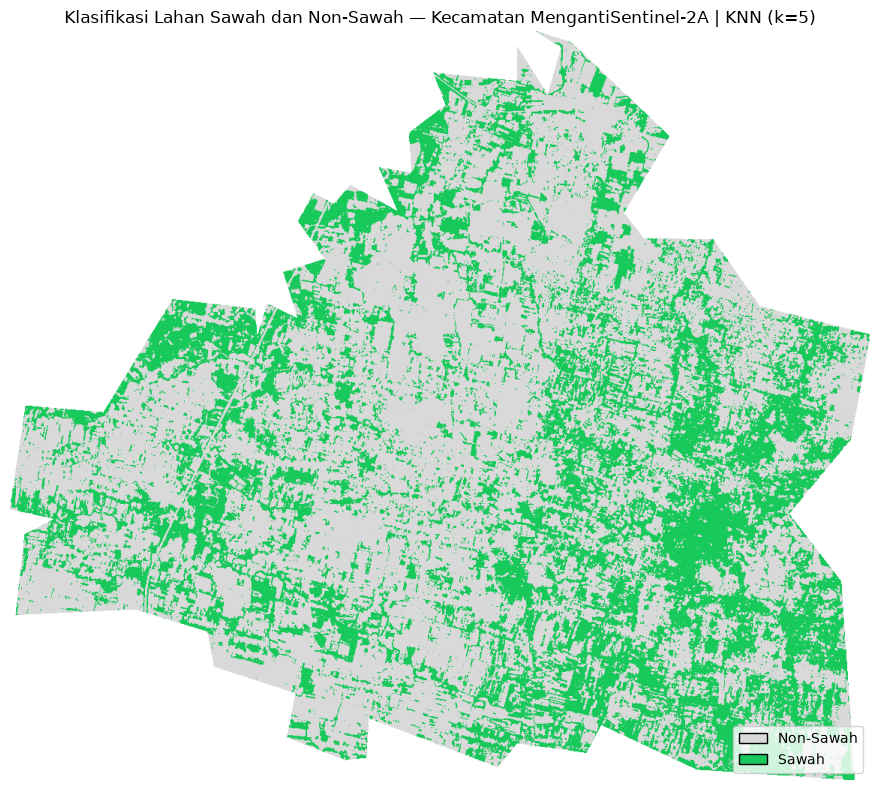

In [14]:
plot_data = classified.astype(float)
plot_data[plot_data == 255] = np.nan

cmap = ListedColormap([
    "#d9d9d9",  # Non-Sawah
    "#18c95b"   # Sawah
])

fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(
    plot_data,
    cmap=cmap,
    vmin=0,
    vmax=1
)

ax.set_title(
    "Klasifikasi Lahan Sawah dan Non-Sawah — Kecamatan Menganti"
    "Sentinel-2A | KNN (k=5)"
)

ax.axis("off")

legend = [
    Patch(
        facecolor="#d9d9d9",
        edgecolor="black",
        label="Non-Sawah"
    ),
    Patch(
        facecolor="#18c95b",
        edgecolor="black",
        label="Sawah"
    )
]

ax.legend(
    handles=legend,
    loc="lower right"
)

plt.tight_layout()
plt.show()


## 15. Menampilkan kembali peta hasil klasifikasi sebagai RGB berbasis class

Kode ini hanya menampilkan hasil klasifikasi dengan warna kelas dan tidak mengubah file GeoTIFF sumber.

### Apa yang dilakukan

Ringkasan akhir dihitung dari pixel valid untuk mendapatkan persentase masing-masing kelas. Bagian ini hanya menyajikan hasil; file GeoTIFF tidak diubah.

In [15]:
# Persentase kelas dari pixel valid
valid_pixels = np.sum(np.isin(classified, [0, 1]))

summary = area_result.copy()
summary["Persentase"] = (
    summary["Pixel"] / valid_pixels * 100
)

display(
    summary.style.format({
        "Luas (m²)": "{:,.2f}",
        "Luas (km²)": "{:.2f}",
        "Persentase": "{:.2f}%"
    })
)


,Kelas,Pixel,Luas (m²),Luas (km²),Persentase
0,Non-Sawah,447857,"44,768,613.14",44.77,63.85%
1,Sawah,253525,"25,342,827.39",25.34,36.15%


# Kesimpulan seluruh proses

### Clustering

Hasil clustering menunjukkan:
- **Linear terbaik:** PCA 37, K=3, Silhouette **0,647**.
- **Polynomial terbaik:** PCA 37, K=7, Silhouette **0,537**.

Visualisasi peta dibuat langsung dengan Python menggunakan Folium sehingga hasil yang ditampilkan di notebook mengikuti peta HTML clustering yang telah dibuat sebelumnya.

### Klasifikasi sawah dan non-sawah

Data klasifikasi terdiri dari **100 sampel**, yaitu 50 sawah dan 50 non-sawah. Hasil perbandingan model menunjukkan bahwa **KNN dan SVM** memperoleh mean accuracy 1,0000 pada 5-fold cross-validation. KNN digunakan sebagai model final dengan `k=5`.

KNN kemudian digunakan untuk mengklasifikasikan seluruh pixel citra Sentinel-2A. Hasil raster memiliki:
- kode `0` = non-sawah;
- kode `1` = sawah;
- kode `255` = NoData.

Hasil klasifikasi yang diperoleh:
- **Sawah: 253.525 pixel ≈ 25,35 km²**
- **Non-Sawah: 447.857 pixel ≈ 44,79 km²**